# In-class project

A baseline Jupyter notebook for an in-class project for learning the materials at [github.com/ale66/learn-coding](https://github.com/ale66/learn-coding/).

Please do no edit this file: rather, make a copy, call it `a-.ipynb` then `git add`, `git commit` and `git push` it to [github.com/ale66/learn-coding-playground-2026-27](https://github.com/ale66/learn-coding-playground-2026-27/).


In [339]:
#Test Commit

In [340]:
#test christine please tell me if it wokred

### Group C

your topic is:

> the Q. with most arrivals (Summer?)\

In [341]:
#Test Commit

### Code below is from the baseline

Change as needed, experiment with data visualisation in Matplotlib.

Do we have all required Python modules?

In [342]:
#!pip install wget

In [343]:
# Setup phase: not needed for Jupyter, uncomment as needed.

# MYWORKDIR = "C:\\Users\\ale\\Downloads\\_git\\learn-coding-playground-2026-27\\migration"

# import os
# os.chdir(MYWORKDIR)

Prepare the wget invisible browser, make it look like human using Firefox 

In [344]:

import os
import urllib.request

myopener = urllib.request.build_opener()

myopener.addheaders = [
    ("User-Agent", "Mozilla/5.0"),
    ("Referer", "https://data.spectator.co.uk/"),
]

urllib.request.install_opener(myopener)

Default setup, change as you see fit.

In [345]:
new_data_file = "data/small-boats.csv"

new_figure = "data/small-boats-c.png"

In [346]:
import wget

# data of the "small boat crossings" chart on data.spectator.co.uk/migration
# these are not all-caps constants: we plan to do this for more than one file

url = "https://datawrapper.dwcdn.net/58WcU/22/dataset.csv"

os.makedirs("data", exist_ok=True)

if os.path.exists(new_data_file):
    os.remove(new_data_file)

fname = wget.download(url, out=new_data_file)

print(f"Data file from {url} saved as {new_data_file}")

# Open the file, import data

Data file from https://datawrapper.dwcdn.net/58WcU/22/dataset.csv saved as data/small-boats.csv


In [347]:
import csv

# Check out the first 5 rows
R = 5

with open(new_data_file) as f:
    reader = csv.reader(f, delimiter="\t")

    for _ in range(R):
        print(next(reader))

# Data ingestion: read data and put it into your lists

['', 'Albanian', 'Total less Albanian']
['2018 Q1', '221', '2400']
['2018 Q2', '250', '2536']
['2018 Q3', '278', '3278']
['2018 Q4', '343', '4071']


Prepare the Python variable for transferring data (aka. Data ingestion).

In [348]:
labels = []
albanians = []
others = []


In [349]:

with open(new_data_file) as f:
    reader = csv.reader(f, delimiter="\t")

    # chuck the first row
    next(reader)
    
    for row in reader:
        labels.append(row[0])
        albanians.append(int(row[1]))
        others.append(int(row[2]))

# preview the data: the first R values
print('This is the data from file ', new_data_file)
print(labels[:R])
print(albanians[:R])
print(others[:R])


This is the data from file  data/small-boats.csv
['2018 Q1', '2018 Q2', '2018 Q3', '2018 Q4', '2019 Q1']
[221, 250, 278, 343, 256]
[2400, 2536, 3278, 4071, 3482]


In [350]:
for i in range(len(labels)):
    if "Q1" in labels[i]:
        print(labels[i], albanians[i] + others[i])

2018 Q1 2621
2019 Q1 3738
2020 Q1 3420
2021 Q1 2751
2022 Q1 6866
2023 Q1 5715
2024 Q1 7584
2025 Q1 8092


In [351]:
for i in range(len(labels)):
    if "Q2" in labels[i]:
        print(labels[i], albanians[i] + others[i])

2018 Q2 2786
2019 Q2 3393
2020 Q2 2959
2021 Q2 6027
2022 Q2 10152
2023 Q2 9115
2024 Q2 9332
2025 Q2 14510


In [352]:
for i in range(len(labels)):
    if "Q3" in labels[i]:
        print(labels[i], albanians[i] + others[i])

2018 Q3 3556
2019 Q3 4645
2020 Q3 6326
2021 Q3 13686
2022 Q3 22429
2023 Q3 14981
2024 Q3 13160


In [353]:
for i in range(len(labels)):
    if "Q4" in labels[i]:
        print(labels[i], albanians[i] + others[i])

2018 Q4 4414
2019 Q4 4505
2020 Q4 4395
2021 Q4 14349
2022 Q4 15255
2023 Q4 6888
2024 Q4 13579


In [354]:
quarters = {
    "Q1": [],
    "Q2": [],
    "Q3": [],
    "Q4": []
}

In [355]:
for i in range(len(labels)):
    if "Q1" in labels[i]:
        quarters["Q1"].append(albanians[i] + others[i])

    if "Q2" in labels[i]:
        quarters["Q2"].append(albanians[i] + others[i])

    if "Q3" in labels[i]:
        quarters["Q3"].append(albanians[i] + others[i])

    if "Q4" in labels[i]:
        quarters["Q4"].append(albanians[i] + others[i])

In [356]:
print("Q1:", sum(quarters["Q1"]))
print("Q2:", sum(quarters["Q2"]))
print("Q3:", sum(quarters["Q3"]))
print("Q4:", sum(quarters["Q4"]))

Q1: 40787
Q2: 58274
Q3: 78783
Q4: 63385


### Visualisation: reproduce the original data display

In [357]:
import matplotlib.pyplot as plt

# our main command: create a 8x5 inches black canvas
fig, ax = plt.subplots(figsize=(9, 5), facecolor="white")

# set the area between the axes
ax.set_facecolor("white")

plt.close(fig)

Select labels for the horizontal axis (the 'x')

To reproduce the plot, we will keep one label in 4, i.e., every year. 

Change this as you see fit.

In [358]:

x = range(len(labels))

tick_pos = []
tick_names = []

for i in x:
    if i % 4 == 0:  # one label every two years
        tick_pos.append(i)
        tick_names.append(labels[i])

# check the work done
print("We'll use these tick positions and labels: ")
print(tick_pos)
print(tick_names)

We'll use these tick positions and labels: 
[0, 4, 8, 12, 16, 20, 24, 28]
['2018 Q1', '2019 Q1', '2020 Q1', '2021 Q1', '2022 Q1', '2023 Q1', '2024 Q1', '2025 Q1']


Prepare the x-axis visualisation

In [359]:
x = range(4)

tick_names = ["Q1", "Q2", "Q3", "Q4"]

ax.set_xticks(x)
ax.set_xticklabels(tick_names)

[Text(0, 0, 'Q1'), Text(1, 0, 'Q2'), Text(2, 0, 'Q3'), Text(3, 0, 'Q4')]

Prepare the y-axis visualisation

In [360]:
ax.yaxis.set_major_formatter("{x:,.0f}")

ax.yaxis.grid(True, color="lightgray", alpha=0.4)

ax.set_axisbelow(True)

ax.tick_params(colors="gray", length=0)

for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

ax.spines["bottom"].set_color("lightgray")



Write a description on top left corner of the data display.

The writing begins in position (0.03, 0.97), try changing as you see fit.

In [361]:
fig.text(0.1, 0.96, "Migrant arrivals by quarter",
         color="black", fontsize=20,
         fontweight="bold", va="top")

fig.text(0.1, 0.88, "Total migrant arrivals, 2018–2025",
         color="gray", fontsize=13, va="top")


Text(0.1, 0.88, 'Total migrant arrivals, 2018–2025')

Draw the data for Albanians.
Change ax.bar for a different visualisation style.

In [362]:
totals = [
    sum(quarters["Q1"]),
    sum(quarters["Q2"]),
    sum(quarters["Q3"]),
    sum(quarters["Q4"])
]

colors = ["lightblue", "lightblue", "steelblue", "lightblue"]

ax.bar(x, totals, width=0.6, color=colors)

for i in range(4):
    ax.text(i, totals[i] + 1000, f"{totals[i]:,}",
            ha="center", color="gray", fontsize=10)


In [363]:
#ax.legend(loc="lower left", bbox_to_anchor=(-0.05, 1.0), ncol=2, frameon=False,
          #labelcolor="white", fontsize=11, handlelength=1, handleheight=1)

Put the data display out.

Set the padding around the data display as a percentage.

Empty space at the top if for title/caption.

In [364]:
# the traditional version does not work well in Jupyter
# plt.subplots_adjust(top=0.75, left=0.1, right=0.9, bottom=0.1)

# plt.savefig(new_figure)
# plt.show()


Functional version:

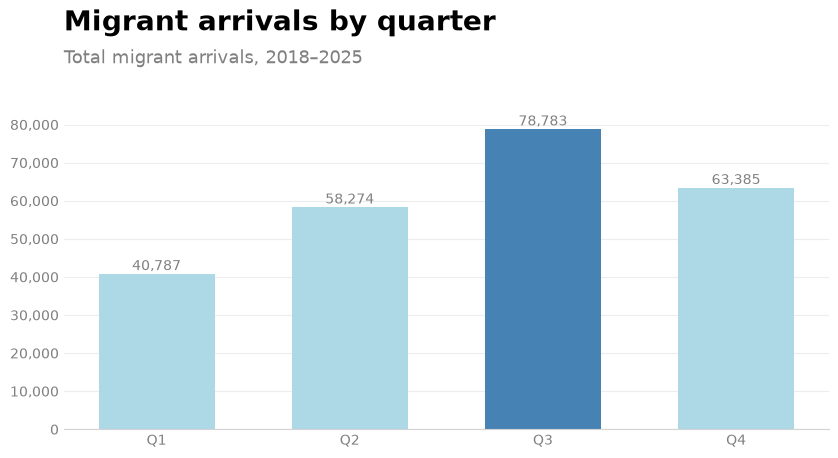

In [365]:
fig.subplots_adjust(top=0.75, left=0.1, right=0.95, bottom=0.12)

fig.savefig(new_figure, facecolor="white", dpi=1000)

display(fig)    # show the finished figure once